<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


## Hands on Lab: Complete the Machine Learning Prediction lab


Estimated time needed: **60** minutes


Space X advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because Space X can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against space X for a rocket launch.   In this lab, you will create a machine learning pipeline  to predict if the first stage will land given the data from the preceding labs.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


Perform exploratory  Data Analysis and determine Training Labels

*   create a column for the class
*   Standardize the data
*   Split into training data and test data

\-Find best Hyperparameter for SVM, Classification Trees and Logistic Regression

*   Find the method performs best using test data


## Import Libraries and Define Auxiliary Functions


In [89]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


We will import the following libraries for the lab


In [90]:
# Pandas: A Python library for efficient data manipulation and analysis.
import pandas as pd
# NumPy: Core library for numerical computing in Python, enabling multi-dimensional arrays and math operations.
import numpy as np
# Matplotlib: A plotting library for creating static, animated, and interactive visualizations in Python.
import matplotlib.pyplot as plt
# Seaborn: A statistical data visualization library built on Matplotlib for creating informative and attractive graphics.
import seaborn as sns
# Scikit-learn preprocessing module: Tools for scaling, normalization, and encoding data.
from sklearn import preprocessing
# Scikit-learn model selection utilities: For splitting data and hyperparameter tuning.
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
# Logistic Regression: A linear model for binary classification using probability distributions.
from sklearn.linear_model import LogisticRegression
# Support Vector Classifier (SVC): Supervised learning model for classification tasks.
from sklearn.svm import SVC
# Decision Tree Classifier: A tree-based model for classification and regression.
from sklearn.tree import DecisionTreeClassifier
# K-Nearest Neighbors: A simple, instance-based learning algorithm for classification and regression.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

This function is to plot the confusion matrix.


In [91]:
def plot_confusion_matrix(y, y_predict):
    """
    Plots the confusion matrix for the given true and predicted labels.

    Parameters:
    y (array-like): Array of true labels (0 = "did not land", 1 = "landed").
    y_predict (array-like): Array of predicted labels (0 = "did not land", 1 = "landed").

    Returns:
    None: Displays the confusion matrix as a visual plot.
    """

    # Compute the confusion matrix using true and predicted labels
    cm = confusion_matrix(y, y_predict)

    # Create a subplot to host the heatmap visualization
    ax = plt.subplot()

    # Generate the heatmap with cell annotations enabled
    # annot=True displays numerical values inside each cell for clear interpretation
    sns.heatmap(cm, annot=True, ax=ax)

    # Define axis labels and plot title for clarity
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix')

    # Assign descriptive class labels to the tick marks
    # These represent the two possible outcomes of rocket landing attempts
    ax.xaxis.set_ticklabels(['did not land', 'landed'])
    ax.yaxis.set_ticklabels(['did not land', 'landed'])

    # Render the plot to the output
    plt.show() 

## Load the dataframe


Load the data


In [92]:
# Read the dataset from part 2 and convert it into a pandas DataFrame
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")

In [93]:
# Print the first few rows of the DataFrame to inspect its contents
data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [94]:
# Read the features dataset from part 3 and convert it into a pandas DataFrame (X) which represents the input features for the model.
X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')

In [95]:
# Print the first 100 rows of the DataFrame to inspect its contents
X.head(100)

,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,Orbit_GTO,Orbit_HEO,Orbit_ISS,...,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062,GridFins_False,GridFins_True,Reused_False,Reused_True,Legs_False,Legs_True
0,1.0,6104.959412,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,2.0,525.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,3.0,677.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,4.0,500.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,5.0,3170.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,86.0,15400.000000,2.0,5.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
86,87.0,15400.000000,3.0,5.0,2.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
87,88.0,15400.000000,6.0,5.0,5.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
88,89.0,15400.000000,3.0,5.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


## TASK  1


Create a NumPy array from the column <code>Class</code> in <code>data</code>, by applying the method <code>to_numpy()</code>  then
assign it  to the variable <code>Y</code>,make sure the output is a  Pandas series (only one bracket df\['name of  column']).


In [96]:
# Create a NumPy array from the 'Class' column in the DataFrame and assign it to the variable Y
Y = data['Class'].to_numpy()

In [ ]:
# Print the first few elements of the NumPy array Y to verify its contents
print(Y)

[0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1
 1 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 0 1
 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1]


(90,)

## TASK  2


Standardize the data in <code>X</code> then reassign it to the variable  <code>X</code> using the transform provided below.


In [98]:
# Standardize the data in X using StandardScaler and reassign it to X
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

We split the data into training and testing data using the  function  <code>train_test_split</code>.   The training data is divided into validation data, a second set used for training  data; then the models are trained and hyperparameters are selected using the function <code>GridSearchCV</code>.


## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


In [99]:
# Split the data into training and testing sets with test_size=0.2 and random_state=2
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

we can see we only have 18 test samples.


In [100]:
# Print the shape of the test set labels
Y_test.shape

(18,)

In [101]:
# Instantiate the empty model list to compare the results of different models
model_results = []

## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [102]:
# Define hyperparameters to be used in GridSearchCV
parameters = {
    'C': [0.01, 0.1, 1.0, 10.0],  # Reduced from 9 values - focus on proven winners
    'penalty': ['l1', 'l2'],       # Keep this - both are valuable
    'solver': ['liblinear', 'saga'],  # Remove 'lbfgs' since it doesn't support L1
    'class_weight': [None, 'balanced', {0: 1, 1: 2}],  # Removed {0:1, 1:3} - diminishing returns
    'max_iter': [1000],            # Single value - convergence issues will show warning
    'tol': [1e-4, 1e-3],           # Removed 1e-2 - too loose for good convergence
    'fit_intercept': [True]        # Usually keep enabled - rarely beneficial to remove
}

# Create the Logistic Regression object.
lr = LogisticRegression()

In [103]:
# Create the GridSearchCV object with cv = 10.
lr_gs_cv = GridSearchCV(lr, parameters, cv=10)

# Fit the object to find the best hyperparameters.
lr_cv = lr_gs_cv.fit(X_train, Y_train)

C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\

In [104]:
# Append the result to the model_results list.
model_results.append({
    'model': 'Logistic Regression',
    'best_params': lr_cv.best_params_,
    'best_score': lr_cv.best_score_
})

We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [105]:
# Print the best hyperparameters and the accuracy on the validation data.
print("Tuned Hyperparameters (best parameters) ", lr_cv.best_params_)
print("Accuracy :", lr_cv.best_score_)

Tuned Hyperparameters (best parameters)  {'C': 0.1, 'class_weight': {0: 1, 1: 2}, 'fit_intercept': True, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'saga', 'tol': 0.0001}
Accuracy : 0.8625


## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


In [106]:
# Calculate accuracy on the test data.
print("Accuracy on the test data:", lr_cv.score(X_test, Y_test))

Accuracy on the test data: 0.8333333333333334


Lets look at the confusion matrix:


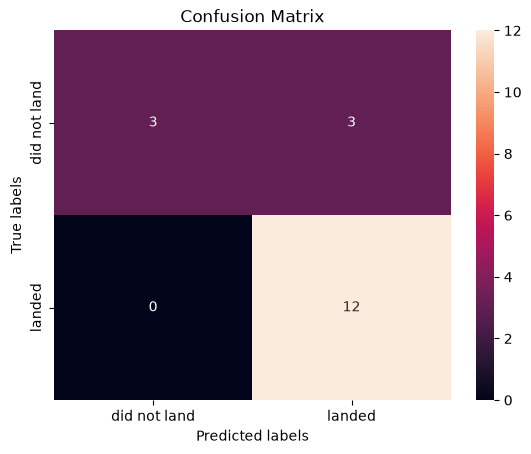

In [107]:
# Print the confusion matrix on the test data.
yhat=lr_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat)

Examining the confusion matrix, we see that logistic regression can distinguish between the different classes.  We see that the problem is false positives.

Overview:

True Postive - 12 (True label is landed, Predicted label is also landed)

False Postive - 3 (True label is not landed, Predicted label is landed)


## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [ ]:
# Define hyperparameters to be used in GridSearchCV
parameters = {
    'kernel': ('linear', 'rbf', 'poly', 'sigmoid'),
    'C': np.logspace(-3, 3, 7),  # Increased from 5 to 7 points
    'gamma': np.logspace(-4, 2, 7),  # Adjusted range and increased resolution
    'class_weight': [None, 'balanced'],
    'degree': [2, 3, 4],  # Only relevant for 'poly' kernel
    'coef0': np.logspace(-2, 1, 5)  # Only relevant for 'poly' and 'sigmoid'
}

# Create the SVM object.
svm = SVC()

In [132]:
# Create the GridSearchCV object with cv = 10.
svm_gs_cv = GridSearchCV(svm, parameters, cv=10)

# Fit the object to find the best hyperparameters.
svm_cv = svm_gs_cv.fit(X_train, Y_train)

In [133]:
# Append the result to the model_results list.
model_results.append({
    'model': 'Support Vector Machines',
    'best_params': svm_cv.best_params_,
    'best_score': svm_cv.best_score_
})

In [134]:
# Print the best hyperparameters and the accuracy on the validation data.
print("Tuned Hyperparameters (best parameters) ", svm_cv.best_params_)
print("Accuracy :", svm_cv.best_score_)

Tuned Hyperparameters (best parameters)  {'C': np.float64(0.01), 'class_weight': None, 'coef0': np.float64(0.01), 'degree': 2, 'gamma': np.float64(0.0001), 'kernel': 'linear'}
Accuracy : 0.8625


## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


In [112]:
# Calculate accuracy on the test data.
print("Accuracy on the test data:", svm_cv.score(X_test, Y_test))

Accuracy on the test data: 0.8333333333333334


We can plot the confusion matrix


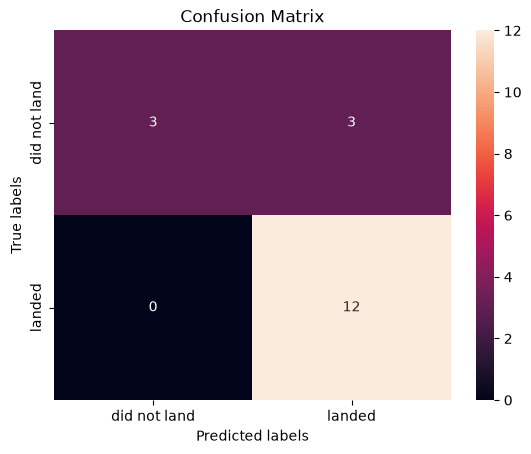

In [113]:
# Print the confusion matrix on the test data.
yhat=svm_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [114]:
# Define hyperparameters to be used in GridSearchCV
# Balanced refinement between the two extremes
balanced_parameters = {
    'criterion': ['gini'],
    'max_depth': [5, 6],                     # Narrow to the effective range
    'max_features': ['sqrt', 'log2'],        # Keep feature selection winners
    'min_samples_leaf': [1, 2, 3, 4],        # Broaden leaf tolerance
    'min_samples_split': [2, 5, 10]          # Test split regularization impact
}

# Create the DecisionTree object.
tree = DecisionTreeClassifier()

In [115]:
# Create the GridSearchCV object with cv = 10.
tree_gs_cv = GridSearchCV(tree, balanced_parameters, cv=10, n_jobs =-1)

# Fit the object to find the best hyperparameters.
tree_cv = tree_gs_cv.fit(X_train, Y_train)

In [116]:
# Append the result to the model_results list.
model_results.append({
    'model': 'Decision Tree',
    'best_params': tree_cv.best_params_,
    'best_score': tree_cv.best_score_
})

In [117]:
# Print the best hyperparameters and the accuracy on the validation data.
print("Tuned Hyperparameters (best parameters) ", tree_cv.best_params_)
print("Accuracy :", tree_cv.best_score_)

Tuned Hyperparameters (best parameters)  {'criterion': 'gini', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Accuracy : 0.8464285714285713


## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


In [118]:
# Calculate accuracy on the test data.
print("Accuracy on the test data:", tree_cv.score(X_test, Y_test))

Accuracy on the test data: 0.8333333333333334


We can plot the confusion matrix


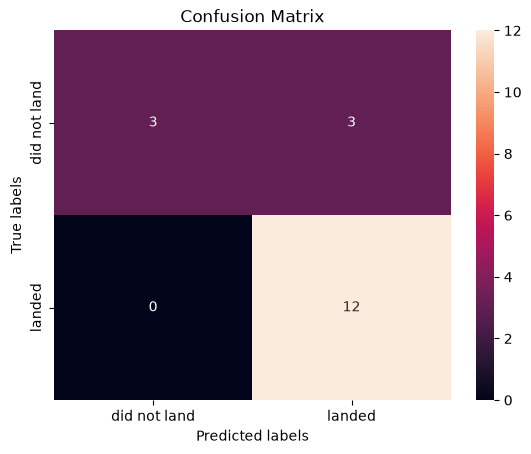

In [119]:
# Print the confusion matrix on the test data.
yhat=tree_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [120]:
# Define hyperparameters to be used in GridSearchCV
parameters_refined = {
    'n_neighbors': [5, 6, 7, 8, 9],  # Focus around winning value
    'algorithm': ['auto', 'brute'],   # Test if brute force is competitive
    'p': [1, 2],                      # Confirm Manhattan preference
    'weights': ['uniform', 'distance']
}

# Create the KNN object.
KNN = KNeighborsClassifier()

In [121]:
# Create the GridSearchCV object with cv = 10.
knn_gs_cv = GridSearchCV(KNN, parameters_refined, cv=10, n_jobs =-1)

# Fit the object to find the best hyperparameters.
knn_cv = knn_gs_cv.fit(X_train, Y_train)

In [122]:
# Append the result to the model_results list.
model_results.append({
    'model': 'K-Nearest Neighbours',
    'best_params': knn_cv.best_params_,
    'best_score': knn_cv.best_score_
})

In [123]:
# Print the best hyperparameters and the accuracy on the validation data.
print("Tuned Hyperparameters (best parameters) ", knn_cv.best_params_)
print("Accuracy :", knn_cv.best_score_)

Tuned Hyperparameters (best parameters)  {'algorithm': 'auto', 'n_neighbors': 7, 'p': 1, 'weights': 'uniform'}
Accuracy : 0.8464285714285713


## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


In [124]:
# Calculate accuracy on the test data.
print("Accuracy on the test data:", knn_cv.score(X_test, Y_test))

Accuracy on the test data: 0.8333333333333334


We can plot the confusion matrix


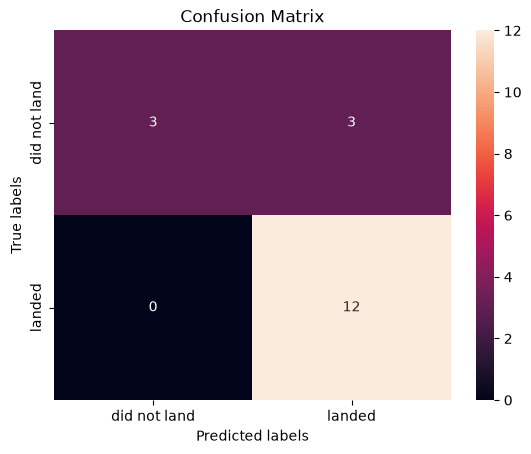

In [125]:
# Print the confusion matrix on the test data.
yhat=knn_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat)

## TASK  12


Find the method performs best:


In [126]:
# Compare results - this line runs after each model
results_df = pd.DataFrame(model_results).sort_values('best_score', ascending=False)
results_df

,model,best_params,best_score
1,Support Vector Machines,"{'C': 1.0, 'class_weight': None, 'coef0': 1.77...",0.875000
0,Logistic Regression,"{'C': 0.1, 'class_weight': {0: 1, 1: 2}, 'fit_...",0.862500
2,Decision Tree,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.846429
3,K-Nearest Neighbours,"{'algorithm': 'auto', 'n_neighbors': 7, 'p': 1...",0.846429


Out of the four models evaluated (Logistic Regression, KNN, Decision Trees, and SVM), 
the Support Vector Machine (SVM) model achieved the highest accuracy (~87%). 

While further hyperparameter tuning may yield marginal improvements, it's crucial to 
balance optimization with methodological rigor. Specifically, we must limit the number 
of tuning-test iterations to avoid overfitting to the test set. The test set should 
only be used once, for final evaluation, while tuning should occur exclusively within 
the training-validation loop via cross-validation.

## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
